# Day 19

In [73]:
import keras
from keras import layers
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import joblib

In [82]:
import warnings
warnings.filterwarnings('ignore')

In [61]:
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 50
EPOCHS = 10
SEED = 123

dataset_path = r".\cats_and_dogs_kaggle_dataset\PetImages"

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(128, 128),
    batch_size=32
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(128, 128),
    batch_size=32
)

Found 24991 files belonging to 2 classes.
Using 19993 files for training.
Found 24991 files belonging to 2 classes.
Using 4998 files for validation.


In [62]:
print(train_ds.class_names)

['Cat', 'Dog']


In [ ]:
# from PIL import Image
# import os

# bad_images = []

# for folder in ["Cat", "Dog"]:
#     folder_path = os.path.join(dataset_path, folder)

#     for filename in os.listdir(folder_path):

#         # Ignore Thumbs.db etc.
#         if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
#             continue

#         file_path = os.path.join(folder_path, filename)

#         try:
#             image_data = tf.io.read_file(file_path)
#             image = tf.io.decode_image(image_data, channels=3)

#         except Exception as e:
#             print("TensorFlow can't decode:", file_path)
#             print(e)
#             print()

#             bad_images.append(file_path)

#             # Remove the problematic image
#             os.remove(file_path)

# print("Total TensorFlow-problematic images removed:", len(bad_images))

In [64]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


In [65]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(
            height_factor=0.1,
            width_factor=0.1
        ),
        layers.RandomContrast(0.1),
    ],
    name="data_augmentation"
)

In [66]:
model = keras.Sequential(
    [
        # Input
        keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

        # Data augmentation
        data_augmentation,

        # Normalize pixel values from 0-255 to 0-1
        layers.Rescaling(1.0 / 255),

        # CNN Block 1
        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        # CNN Block 2
        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        # CNN Block 3
        layers.Conv2D(
            128, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        # Convert feature maps into a vector
        layers.Flatten(),

        # Fully connected layers
        layers.Dense(128, activation="relu"),

        # Reduce overfitting
        layers.Dropout(0.5),

        # Binary classification output
        layers.Dense(1, activation="sigmoid")
    ],
    name="cat_dog_cnn"
)

In [67]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


# Display model architecture
model.summary()

Model: "cat_dog_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [68]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [69]:
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=test_ds,
    callbacks=[early_stopping]
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 199s 316ms/step - accuracy: 0.6072 - loss: 0.6581 - val_accuracy: 0.6773 - val_loss: 0.6055
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 190s 304ms/step - accuracy: 0.6910 - loss: 0.5865 - val_accuracy: 0.7069 - val_loss: 0.5686
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 191s 306ms/step - accuracy: 0.7243 - loss: 0.5484 - val_accuracy: 0.7253 - val_loss: 0.5487
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 188s 301ms/step - accuracy: 0.7453 - loss: 0.5184 - val_accuracy: 0.7753 - val_loss: 0.4714
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 187s 299ms/step - accuracy: 0.7599 - loss: 0.4981 - val_accuracy: 0.8061 - val_loss: 0.4355
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 188s 301ms/step - accuracy: 0.7761 - loss: 0.4728 - val_accuracy: 0.8037 - val_loss: 0.4258
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 792s 1s/step - accuracy: 0.7848 - loss: 0.4593 - val_accuracy: 0.8247 - val_loss: 0.3983
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 171s 274ms/step - accuracy: 0.7960 - lo

In [70]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step - accuracy: 0.8439 - loss: 0.3590

Test Loss: 0.35897162556648254
Test Accuracy: 0.8439375758171082


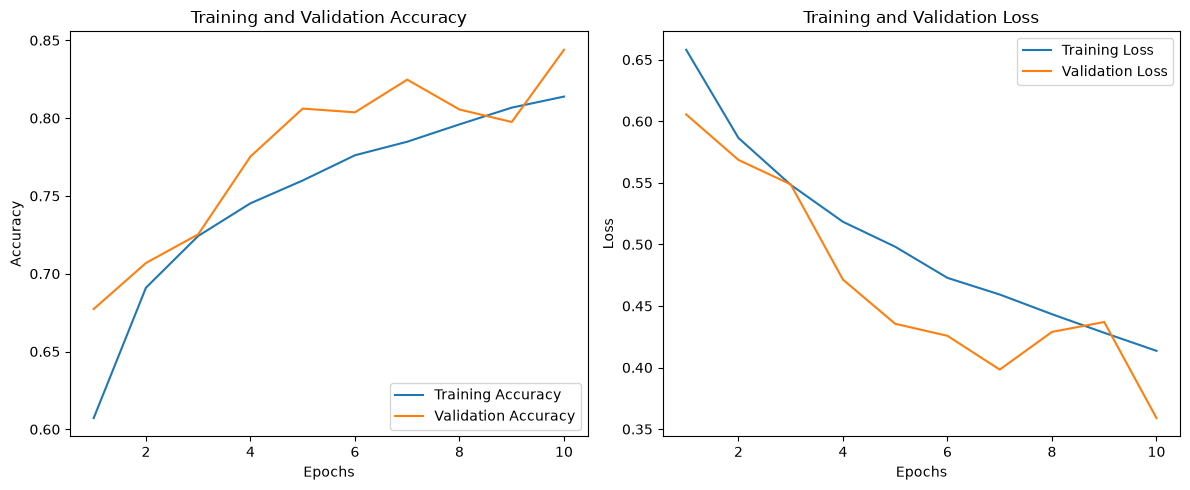

In [71]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    acc,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_acc,
    label="Validation Accuracy"
)

plt.legend(loc="lower right")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")


# Loss plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    loss,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_loss,
    label="Validation Loss"
)

plt.legend(loc="upper right")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.tight_layout()

plt.savefig("cnn_training_results.png")

plt.show()

In [75]:
model.save("cat_dog_cnn.keras")
print("\nModel saved successfully!")


Model saved successfully!


In [90]:
try:
    model = keras.models.load_model("cat_dog_cnn.keras")
    class_names = ['Cat', 'Dog']
    print("Model loaded successfully.")

except (FileNotFoundError, OSError):
    print("Model not found.")

Model loaded successfully.


In [97]:
PREDICTION_IMAGE = r'.\cats_and_dogs_kaggle_dataset\Test Images\cat6.jpg'

test_image = keras.utils.load_img(
    PREDICTION_IMAGE,
    target_size=(IMG_HEIGHT, IMG_WIDTH)
)

test_image = keras.utils.img_to_array(test_image)

test_image = np.expand_dims(test_image, axis=0)

prediction = model.predict(test_image)

probability = round(float(prediction[0][0]),2)

predicted_class = (
    class_names[1]
    if probability >= 0.5
    else class_names[0]
)

print("Predicted Class:", predicted_class)
print("Dog probability:", probability)
print("Cat probability:", 1 - probability)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted Class: Cat
Dog probability: 0.01
Cat probability: 0.99
